# Braun et al. (2026), Supp. Fig. 1 — training succeeds; matrices differ before and after training

> A–D: target sequences (reference a = 0.5, σ = 1.7 s, b = 0; then b = 0.4, σ = 1 s, a = 1). E: mean target–response
> correlation over 50 realisations against training iteration (300) and 10 test iterations; mean absolute weight change
> per iteration. F: performance against amplitude, width, offset (in the Supp. 3 notebook, which owns the sweeps).
> G: weights of realisation 1 against realisation 50 before and after training.

**Panels:** A–D targets · E training curves · G weight scatter.

Uses the Fig. 1 run (`configs/wp0/braun_fig1.yaml`, final settings).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet.targets import SequenceSpec

style()
fig = Figure("wp0", "braun_supp1")
c1 = Figure("wp0", "braun_fig1").config(); tg = c1["target"]
run = wp0.get(tg["amp"], tg["width"], tg["offset"], c1["settings"], store_full=c1["store_full"])
S = run.summary; n_tr = run.meta["config"]["n_train"]; n_te = run.meta["config"]["n_test"]
run.meta["settings"], run.meta["n_realizations"]

('final', 50)

## Panels A–D — target sequences (two periods)

In [2]:
t = np.arange(0, 17, 0.129)
specs = {"A reference": (0.5, 1.7, 0.0), "B offset 0.4": (0.5, 1.7, 0.4), "C width 1 s": (0.5, 1.0, 0.0), "D amplitude 1": (1.0, 1.7, 0.0)}
fig.save("ABCD_targets", t=t, **{k.split()[0]: SequenceSpec(amp=a, width=w, offset=b).rates(t).astype(np.float32) for k, (a, w, b) in specs.items()})

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp1/ABCD_targets.npz')

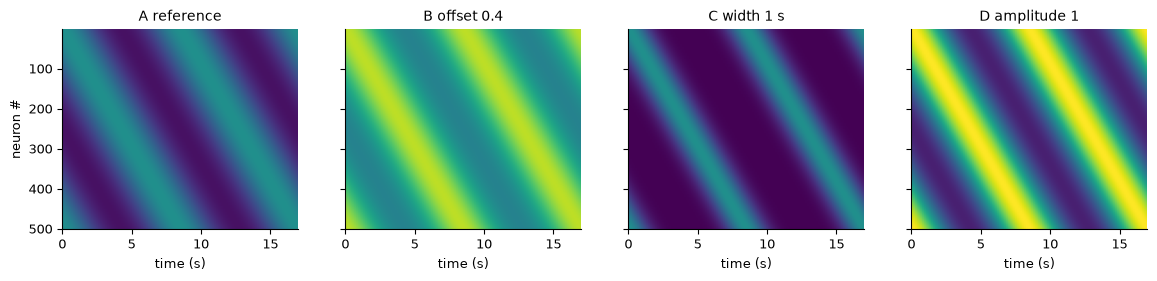

In [3]:
d = fig.load("ABCD_targets")
F, axs = plt.subplots(1, 4, figsize=(14, 2.6), sharey=True)
for ax, k in zip(axs, specs):
    ax.imshow(d[k.split()[0]], aspect="auto", extent=[0, 17, 501, 1], vmin=0, vmax=1); ax.set_title(k); ax.set_xlabel("time (s)")
axs[0].set_ylabel("neuron #")
fig.savefig("ABCD_targets", F); plt.show()

## Panel E — training curves (mean ± SD over realisations) and mean |ΔW| per iteration (Braun eq. 10)

In [4]:
fig.save("E_training", corr_mean=S["corr"].mean(0), corr_sd=S["corr"].std(0), dW_mean=S["dW"].mean(0), n_train=n_tr, n_test=n_te)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp1/E_training.npz')

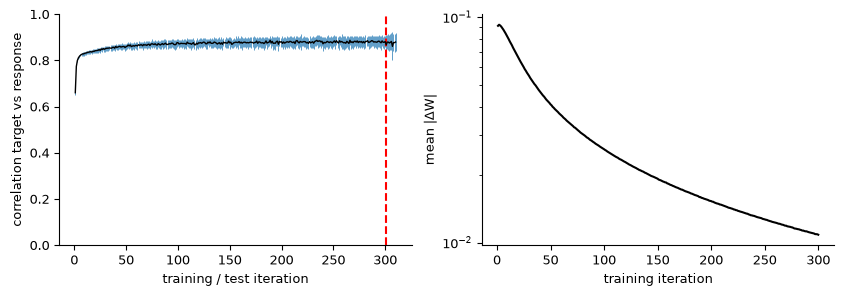

test correlation (mean over test iterations and realisations): 0.876


In [5]:
d = fig.load("E_training"); q = np.arange(1, d["corr_mean"].size + 1)
F, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].errorbar(q, d["corr_mean"], yerr=d["corr_sd"], color="k", ecolor="tab:blue", lw=1, elinewidth=0.5)
axs[0].axvline(int(d["n_train"]) + 0.5, color="r", ls="--"); axs[0].set_ylim(0, 1); axs[0].set_xlabel("training / test iteration"); axs[0].set_ylabel("correlation target vs response")
axs[1].plot(q[: int(d["n_train"])], d["dW_mean"][: int(d["n_train"])], "k"); axs[1].set_yscale("log"); axs[1].set_xlabel("training iteration"); axs[1].set_ylabel("mean |ΔW|")
fig.savefig("E_training", F); plt.show()
print("test correlation (mean over test iterations and realisations): %.3f" % d["corr_mean"][-int(d["n_test"]):].mean())

## Panel G — realisation 1 vs realisation 50, before and after training (diagonal highlighted)

In [6]:
last = run.meta["n_realizations"] - 1
A0, B0, A1, B1 = run.W0(0), run.W0(last), run.W(0), run.W(last)
idx = np.random.default_rng(0).choice(A1.size, 20000, replace=False)
dg = np.arange(A1.shape[0]) * (A1.shape[0] + 1)
fig.save("G_scatter", before=np.stack([A0.ravel()[idx], B0.ravel()[idx]]), after=np.stack([A1.ravel()[idx], B1.ravel()[idx]]),
         after_diag=np.stack([A1.ravel()[dg], B1.ravel()[dg]]), before_diag=np.stack([A0.ravel()[dg], B0.ravel()[dg]]))

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp1/G_scatter.npz')

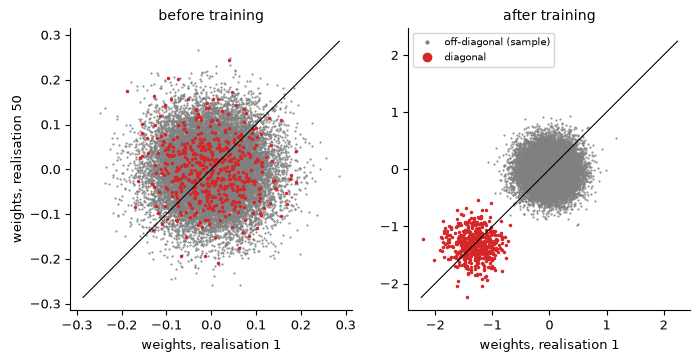

In [7]:
d = fig.load("G_scatter")
F, axs = plt.subplots(1, 2, figsize=(8, 3.8))
for ax, k, title in zip(axs, ["before", "after"], ["before training", "after training"]):
    ax.plot(*d[k], ".", ms=1, color="0.5", label="off-diagonal (sample)"); ax.plot(*d[k + "_diag"], ".", ms=3, color="tab:red", label="diagonal")
    lim = np.abs(np.concatenate([d[k].ravel(), d[k + "_diag"].ravel()])).max(); ax.plot([-lim, lim], [-lim, lim], "k", lw=0.8)
    ax.set_title(title); ax.set_xlabel("weights, realisation 1"); ax.set_aspect("equal")
axs[0].set_ylabel(f"weights, realisation {run.meta['n_realizations']}"); axs[1].legend(fontsize=7, markerscale=4)
fig.savefig("G_scatter", F); plt.show()

## Acceptance

In [8]:
d = fig.load("G_scatter"); e = fig.load("E_training")
dm = d["after_diag"].mean()
fig.checks([
    {"item": "Supp. 1G separate cluster is the diagonal", "criterion": "after training the mean self-weight lies far below the off-diagonal mass (< -3 SD)",
     "value": {"mean_diag": float(dm), "offdiag_mean": float(d["after"].mean()), "offdiag_sd": float(d["after"].std())},
     "passed": bool(dm < d["after"].mean() - 3 * d["after"].std())},
    {"item": "test correlation about 0.8", "criterion": "|x - 0.8| < 0.1", "value": float(e["corr_mean"][-int(e["n_test"]):].mean()),
     "passed": bool(abs(e["corr_mean"][-int(e["n_test"]):].mean() - 0.8) < 0.1)},
])

[PASS] Supp. 1G separate cluster is the diagonal: {'mean_diag': -1.3103794865246827, 'offdiag_mean': -0.010838206679889488, 'offdiag_sd': 0.25401305082997155}
[PASS] test correlation about 0.8: 0.8756385513084229


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp1/acceptance.json')